# Error Analysis: Qwen SFT vs ModernBERT
Which intents each model gets wrong, what it confuses them with, and whether the two models make the same mistakes.
Budgets: **k5** (few labels) and **full** (all labels). Results are pooled over 3 seeds. Test set only.

In [1]:
#Setup- run from the repo root and load the team's evaluation helpers
import os, sys
if os.path.basename(os.getcwd()) == "notebooks":
    os.chdir("..")
sys.path.insert(0, "scripts")

import pandas as pd
import evaluation as ev
print(os.getcwd())

/Users/shuchivardan/github/DATASCI266-Banking77-Encoder-vs-Decoder


In [2]:
# Settings: if model names or budgets change, edit only this cell
MODELS  = ["qwen_sft", "modernbert_min300"]                 # models compared
BUDGETS = ["k5", "full"]                                    # budgets analyzed in detail
ALL_BUDGETS = [b for b in ev.BUDGETS if b != "zeroshot"]    # k1 ... full, for the unmatched table
ZERO_SHOT = list(ev.ZERO_SHOT_MODELS)                       # qwen_zeroshot, frontier (from evaluation.py)

In [3]:
# Load predictions Qwen SFT and ModernBERT at k5 and full, 3 seeds each: 12 test files.

runs = {}
for m in MODELS:
    for b in BUDGETS:
        for s in ev.SEEDS:
            runs[(m, b, s)] = ev.load_predictions(ev.RESULTS / f"{m}_{b}_seed{s}_test.csv")

print(len(runs), "runs loaded")

12 runs loaded


In [4]:
# Overall accuracy per model and budget (mean of 3 seeds), for reference in the findings
acc = {(m, b): sum(ev.score(runs[(m, b, s)])["accuracy"] for s in ev.SEEDS) / len(ev.SEEDS)
       for m in MODELS for b in BUDGETS}
display(pd.Series(acc).round(3).unstack().rename_axis(index="model", columns="budget"))

budget,full,k5
model,,
modernbert_min300,0.936,0.644
qwen_sft,0.939,0.744


### Per-intent performance
For each intent, pooled over seeds:
- **TP**: correctly predicted
- **FP**: other intents wrongly predicted as this one
- **FN**: this intent missed (includes Qwen's unmatched answers). This was the correct intent, but the model predicted something else
- **F1**: one score per intent

Shows the 10 weakest intents per model and budget. Each intent has 120 test predictions (40 × 3 seeds).

In [5]:
names = ev.label_names()

def per_intent_table(model, budget):
    """TP/FP/FN and F1 per intent, pooled over the 3 seeds."""
    df = pd.concat([runs[(model, budget, s)] for s in ev.SEEDS])
    y, p = df["true_label"], df["predicted_label"]
    rows = []
    for i, name in enumerate(names):
        tp = ((y == i) & (p == i)).sum()
        fp = ((y != i) & (p == i)).sum()
        fn = ((y == i) & (p != i)).sum()
        rows.append({"intent": name, "TP": tp, "FP": fp, "FN": fn,
                     "F1": round(2 * tp / (2 * tp + fp + fn), 3)})
    return pd.DataFrame(rows)

In [6]:
from IPython.display import display

def worst_side_by_side(budget, n=10):
    q = per_intent_table("qwen_sft", budget).sort_values("F1").head(n).reset_index(drop=True)
    e = per_intent_table("modernbert_min300", budget).sort_values("F1").head(n).reset_index(drop=True)

    shared = set(q["intent"]) & set(e["intent"])
    for t in (q, e):
        t["intent"] = [f"★ {i}" if i in shared else i for i in t["intent"]]

    side = pd.concat({"Qwen": q, "MB": e}, axis=1)
    side.index = range(1, n + 1)
    side.index.name = "rank"
    print(f"{budget}: 10 weakest intents per model (★ = in both lists, {len(shared)} shared)")
    display(side)

for b in BUDGETS:
    worst_side_by_side(b)

k5: 10 weakest intents per model (★ = in both lists, 6 shared)


Qwen                       \
                                         intent  TP   FP   FN     F1   
rank                                                                   
1                          ★ topping_up_by_card  20   10  100  0.267   
2              ★ top_up_by_bank_transfer_charge  54   98   66  0.397   
3                   get_disposable_virtual_card  37   19   83  0.420   
4          ★ transfer_not_received_by_recipient  64   81   56  0.483   
5                      ★ reverted_card_payment?  55   33   65  0.529   
6                   card_payment_not_recognised  62   51   58  0.532   
7                cash_withdrawal_not_recognised  47    8   73  0.537   
8     ★ balance_not_updated_after_bank_transfer  58   32   62  0.552   
9                       ★ declined_card_payment  90  109   30  0.564   
10                        transfer_into_account  78   72   42  0.578   

                                             MB                     
                                         intent  TP  FP  FN     F1  
rank                                                                
1     ★ balance_not_updated_after_bank_transfer  34  42  86  0.347  
2                       ★ declined_card_payment  42  61  78  0.377  
3                                 top_up_failed  45  62  75  0.396  
4              ★ top_up_by_bank_transfer_charge  37  25  83  0.407  
5                      ★ reverted_card_payment?  62  98  58  0.443  
6          ★ transfer_not_received_by_recipient  59  84  61  0.449  
7       wrong_exchange_rate_for_cash_withdrawal  55  68  65  0.453  
8                          ★ topping_up_by_card  47  34  73  0.468  
9                      declined_cash_withdrawal  52  45  68  0.479  
10                               pending_top_up  55  54  65  0.480

full: 10 weakest intents per model (★ = in both lists, 8 shared)


Qwen                      \
                                         intent   TP  FP  FN     F1   
rank                                                                  
1                            ★ pending_transfer   98  21  22  0.820   
2     ★ balance_not_updated_after_bank_transfer   96  16  24  0.828   
3                 ★ card_payment_not_recognised  102  20  18  0.843   
4                              compromised_card  103  20  17  0.848   
5                          ★ topping_up_by_card  100  14  20  0.855   
6                           ★ declined_transfer   90   0  30  0.857   
7          ★ transfer_not_received_by_recipient  109  23  11  0.865   
8                       ★ fiat_currency_support  104  13  16  0.878   
9                             ★ top_up_reverted  104  12  16  0.881   
10                        declined_card_payment  111  18   9  0.892   

                                             MB                      
                                         intent   TP  FP  FN     F1  
rank                                                                 
1     ★ balance_not_updated_after_bank_transfer   95  20  25  0.809  
2                            ★ pending_transfer   95  15  25  0.826  
3                          ★ topping_up_by_card   94   8  26  0.847  
4          ★ transfer_not_received_by_recipient  104  21  16  0.849  
5                             ★ top_up_reverted  102  18  18  0.850  
6                       ★ fiat_currency_support  101  15  19  0.856  
7                 ★ card_payment_not_recognised  101  11  19  0.871  
8                               failed_transfer  112  25   8  0.872  
9                           ★ declined_transfer   96   3  24  0.877  
10                                 card_arrival  107  16  13  0.881

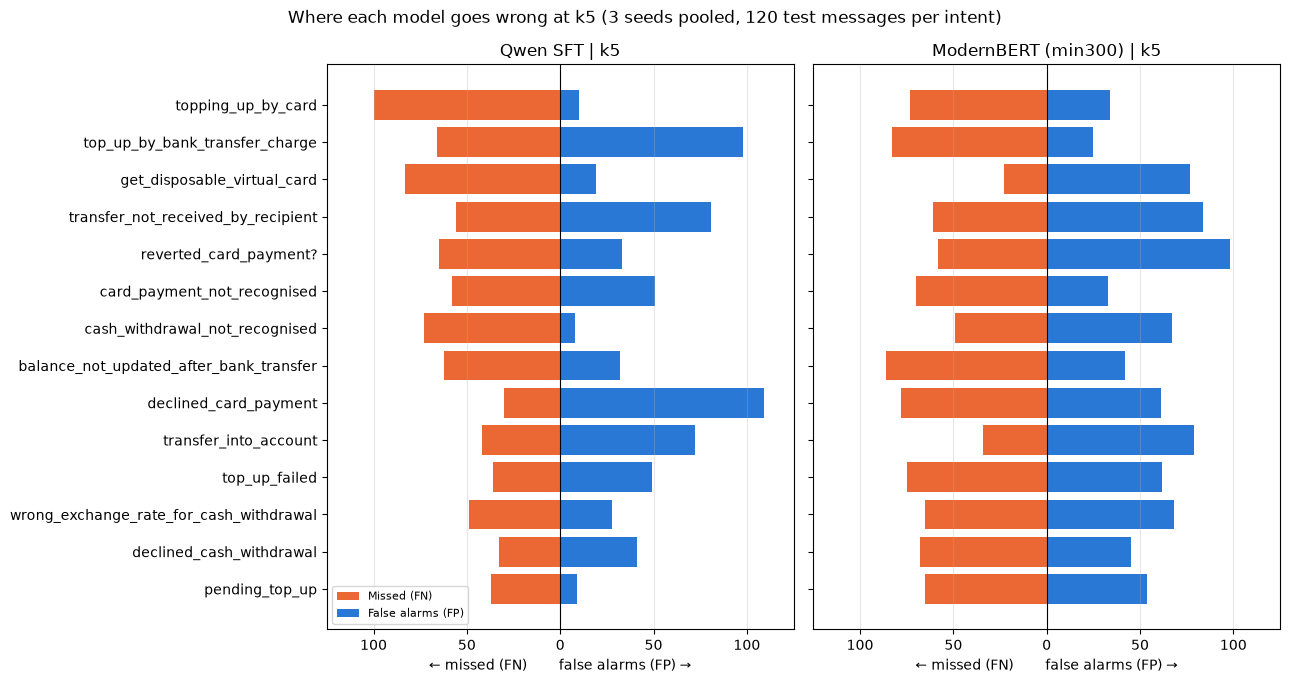

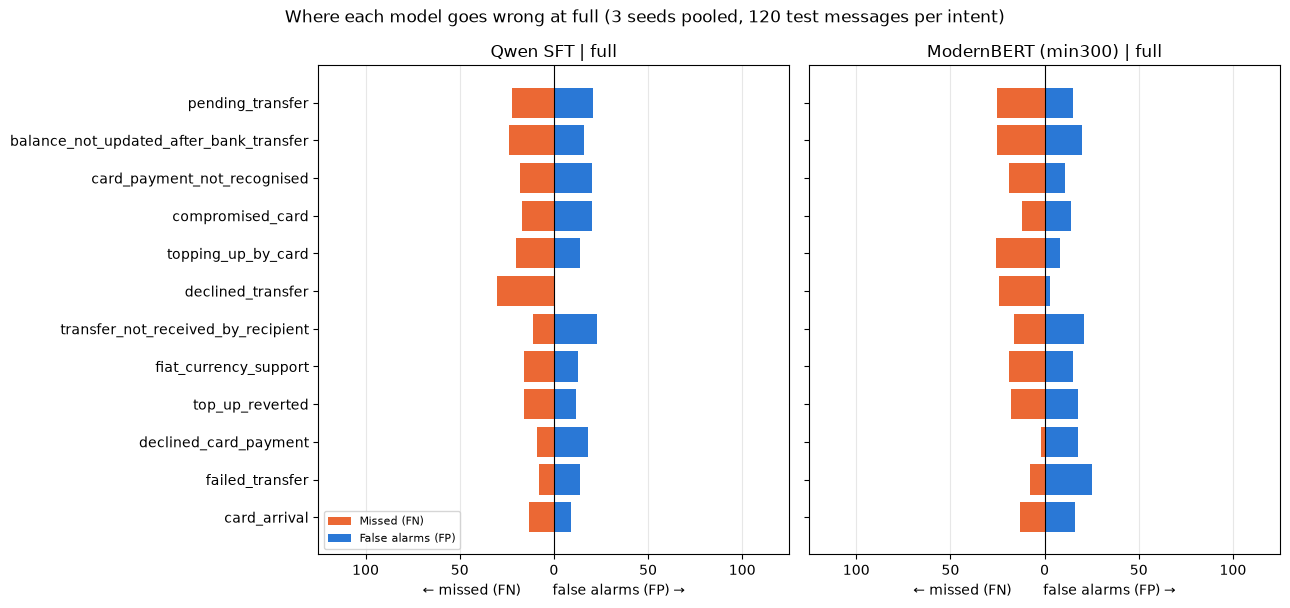

In [7]:
import matplotlib.pyplot as plt

def plot_fp_fn(budget, n=10):
    tables = {"Qwen SFT": per_intent_table("qwen_sft", budget).set_index("intent"),
              "ModernBERT (min300)": per_intent_table("modernbert_min300", budget).set_index("intent")}
    # intents in either model's 10 worst
    worst = []
    for t in tables.values():
        worst += [i for i in t.sort_values("F1").index[:n] if i not in worst]

    fig, axes = plt.subplots(1, 2, figsize=(13, 0.38 * len(worst) + 1.6), sharey=True)
    for ax, (title, t) in zip(axes, tables.items()):
        t = t.loc[worst]
        ax.barh(worst, -t["FN"], color="#eb6834", label="Missed (FN)")
        ax.barh(worst, t["FP"], color="#2a78d6", label="False alarms (FP)")
        ax.axvline(0, color="black", linewidth=0.8)
        ax.set_xlim(-125, 125)
        ax.xaxis.set_major_formatter(lambda x, pos: f"{abs(int(x))}")
        ax.set_title(f"{title} | {budget}")
        ax.set_xlabel("← missed (FN)        false alarms (FP) →")
        ax.grid(axis="x", alpha=0.3)
    axes[0].invert_yaxis()
    axes[0].legend(loc="lower left", fontsize=8)
    fig.suptitle(f"Where each model goes wrong at {budget} (3 seeds pooled, 120 test messages per intent)")
    plt.tight_layout()
    plt.show()

plot_fp_fn("k5")
plot_fp_fn("full")

**Findings:**
- **k5:** The models share 6 of their 10 weakest intents, two each from three families of similar requests (top-ups, transfers, card payments). Qwen's worst intent scores lower than ModernBERT's worst (F1 0.27 vs 0.35), even though Qwen is more accurate overall, so its errors are less even. Qwen over-uses some labels (declined_card_payment: 109 false alarms vs 30 misses) and largely misses others (topping_up_by_card: 100 of 120 missed). ModernBERT's errors are mostly more balanced between misses and false alarms.

- **full:** The weakest intents converge (8 of 10 shared) and score almost the same for both models (F1 0.81–0.89), suggesting the remaining errors come from intents that are hard to tell apart rather than from model type. declined_transfer is often missed (24–30 of 120) but almost never wrongly predicted (0–3 false alarms).

### Most confused pairs
The 10 most frequent mistakes (true intent vs. predicted intent) per model, pooled over 3 seeds.
★ marks pairs that appear in both models' top 10. "unmatched" = Qwen gave a name that is not one of the 77 intents.

In [8]:
def pooled(model, budget):
    return pd.concat([runs[(model, budget, s)] for s in ev.SEEDS])

def pairs_side_by_side(budget, n=10):
    q = ev.top_confusions(pooled("qwen_sft", budget), n)
    e = ev.top_confusions(pooled("modernbert_min300", budget), n)

    shared = set(zip(q["true"], q["predicted"])) & set(zip(e["true"], e["predicted"]))
    for t in (q, e):
        t["true"] = [f"★ {a}" if (a, b) in shared else a for a, b in zip(t["true"], t["predicted"])]

    side = pd.concat({"Qwen": q, "MB": e}, axis=1)
    side.index = range(1, n + 1)
    side.index.name = "rank"
    print(f"{budget}: top {n} confused pairs per model (★ = in both lists, {len(shared)} shared)")
    display(side)

for b in BUDGETS:
    pairs_side_by_side(b)

k5: top 10 confused pairs per model (★ = in both lists, 1 shared)


Qwen  \
                                         true   
rank                                            
1                 get_disposable_virtual_card   
2                       top_up_by_card_charge   
3                      reverted_card_payment?   
4                       transfer_into_account   
5                      card_delivery_estimate   
6              top_up_by_bank_transfer_charge   
7                       ★ why_verify_identity   
8                          topping_up_by_card   
9                                card_arrival   
10    balance_not_updated_after_bank_transfer   

                                                \
                               predicted count   
rank                                             
1                   getting_virtual_card    60   
2         top_up_by_bank_transfer_charge    32   
3                  declined_card_payment    27   
4         top_up_by_bank_transfer_charge    26   
5                           card_arrival    24   
6                   transfer_fee_charged    24   
7                     verify_my_identity    22   
8         top_up_by_bank_transfer_charge    22   
9                 card_delivery_estimate    22   
10    transfer_not_received_by_recipient    21   

                                           MB  \
                                         true   
rank                                            
1                       ★ why_verify_identity   
2     wrong_exchange_rate_for_cash_withdrawal   
3                       declined_card_payment   
4                               top_up_limits   
5                      disposable_card_limits   
6                          verify_my_identity   
7                              pending_top_up   
8              top_up_by_bank_transfer_charge   
9                               exchange_rate   
10                            top_up_reverted   

                                                     
                                    predicted count  
rank                                                 
1                          verify_my_identity    39  
2            card_payment_wrong_exchange_rate    34  
3                      reverted_card_payment?    33  
4                       top_up_by_card_charge    27  
5                 get_disposable_virtual_card    26  
6                         why_verify_identity    26  
7                               top_up_failed    22  
8                       top_up_by_card_charge    21  
9     wrong_exchange_rate_for_cash_withdrawal    21  
10                              top_up_failed    19

full: top 10 confused pairs per model (★ = in both lists, 8 shared)


Qwen  \
                                           true   
rank                                              
1                 ★ card_payment_not_recognised   
2                                ★ card_arrival   
3                            ★ pending_transfer   
4     ★ balance_not_updated_after_bank_transfer   
5                           ★ declined_transfer   
6                      ★ card_delivery_estimate   
7                               top_up_reverted   
8                              pending_transfer   
9                            ★ exchange_via_app   
10                      ★ fiat_currency_support   

                                                     \
                                    predicted count   
rank                                                  
1                            compromised_card    15   
2                      card_delivery_estimate    10   
3          transfer_not_received_by_recipient    10   
4                             transfer_timing    10   
5                       declined_card_payment     9   
6                                card_arrival     9   
7                               top_up_failed     9   
8     balance_not_updated_after_bank_transfer     8   
9                       fiat_currency_support     8   
10                           exchange_via_app     8   

                                             MB  \
                                           true   
rank                                              
1                       ★ fiat_currency_support   
2       balance_not_updated_after_bank_transfer   
3                 ★ card_payment_not_recognised   
4                                ★ card_arrival   
5     ★ balance_not_updated_after_bank_transfer   
6                            ★ pending_transfer   
7                           ★ declined_transfer   
8                            ★ exchange_via_app   
9                      ★ card_delivery_estimate   
10                              exchange_charge   

                                                
                               predicted count  
rank                                            
1                       exchange_via_app    12  
2     transfer_not_received_by_recipient    11  
3                       compromised_card    11  
4                 card_delivery_estimate    10  
5                        transfer_timing     9  
6     transfer_not_received_by_recipient     9  
7                  declined_card_payment     9  
8                  fiat_currency_support     8  
9                           card_arrival     7  
10                         exchange_rate     7

**Findings (k5):**
- Only one confused pair is shared: why_verify_identity → verify_my_identity, which our EDA also found to be the most similar pair of intents.
- Several of Qwen's top mistakes are between intents with similar names: half of get_disposable_virtual_card goes to getting_virtual_card (60 of 120), and top_up_by_card_charge goes to top_up_by_bank_transfer_charge (32). This suggests that with few examples, Qwen leans on the intent names in the prompt (tested with name similarity below).
- top_up_by_bank_transfer_charge acts as a default label for Qwen, absorbing 80 of its 98 false alarms from three related intents.
- ModernBERT's confusions mostly stay within topic families (identity, exchange rate, top-up). The same pair can flip direction between models: Qwen sends reverted_card_payment? to declined_card_payment (27), ModernBERT does the reverse (33).

**Findings (full):**
- The two models now make nearly the same mistakes: 8 of 10 confused pairs are shared, with similar counts.
- Remaining confusions are between intents that overlap in meaning (card_payment_not_recognised → compromised_card; card_arrival ↔ card_delivery_estimate; fiat_currency_support ↔ exchange_via_app), often in both directions, so some messages may fit either label.
- declined_transfer is mostly confused with declined_card_payment (9 for each model).
- Errors are small: the top pair is 15 of 120 (vs 60 of 120 at k5).

### Unmatched answers (decoders only)
How often a decoder outputs a name that is not one of the 77 intents (counted as wrong):
- Qwen and Claude Opus 5.5 ("frontier"), zero-shot
- Qwen fine-tuned, from k1 to full

*Also shows the most common invented names.*

In [9]:
def pct(series):
    return round(100 * series.mean(), 1)

rows = []
# Zero-shot models (one seed each)
for m in ZERO_SHOT:
    df = ev.load_predictions(ev.RESULTS / f"{m}_zeroshot_seed0_test.csv")
    rows.append({"model": m, "budget": "zeroshot",
                 "accuracy_%": pct(df["predicted_label"] == df["true_label"]),
                 "unmatched_%": pct(df["predicted_label"] == -1)})

# Qwen fine-tuned, mean of 3 seeds per budget
for b in ALL_BUDGETS:
    df = pd.concat([ev.load_predictions(ev.RESULTS / f"qwen_sft_{b}_seed{s}_test.csv") for s in ev.SEEDS])
    rows.append({"model": "qwen_sft", "budget": b,
                 "accuracy_%": pct(df["predicted_label"] == df["true_label"]),
                 "unmatched_%": pct(df["predicted_label"] == -1)})
display(pd.DataFrame(rows))

# Invented names: each zero-shot model, then Qwen SFT at k1 (3 seeds pooled)
for m in ZERO_SHOT:
    df = ev.load_predictions(ev.RESULTS / f"{m}_zeroshot_seed0_test.csv")
    print(f"Invented names, {m} (zero-shot):")
    display(df[df["predicted_label"] == -1]["raw_output"].value_counts().head(5))

k1 = pd.concat([ev.load_predictions(ev.RESULTS / f"qwen_sft_k1_seed{s}_test.csv") for s in ev.SEEDS])
print("Invented names, Qwen SFT at k1:")
display(k1[k1["predicted_label"] == -1]["raw_output"].value_counts().head(10))

,model,budget,accuracy_%,unmatched_%
0,qwen_zeroshot,zeroshot,42.1,6.0
1,frontier,zeroshot,88.0,0.0
2,qwen_sft,k1,49.3,16.5
3,qwen_sft,k3,64.6,8.3
4,qwen_sft,k5,74.4,3.5
5,qwen_sft,k10,83.1,1.7
6,qwen_sft,k20,88.0,1.1
7,qwen_sft,k30,90.8,0.6
8,qwen_sft,p50,92.4,0.3
9,qwen_sft,full,93.9,0.2


Invented names, qwen_zeroshot (zero-shot):


raw_output
refund_not_showed_up      23
exchange_currency         17
refund_not_shown_up       15
top_up_by_cheque           8
cheque_or_cash_deposit     6
Name: count, dtype: int64

Invented names, frontier (zero-shot):


raw_output
topup_reverted? Let me pick from the list exactly.\n\ntop_up_reverted    1
Name: count, dtype: int64

Invented names, Qwen SFT at k1:


raw_output
identity_verification     46
auto_top_up               38
getting_physical_card     38
refunded_card_payment?    27
linking                   25
bank_transfer_charge      20
automated_atm_support     19
cheque_or_cash_deposit    16
cancelled_card_payment    16
cancelled_transfer        14
Name: count, dtype: int64

**Findings:**
- With the same prompt and intent list, Qwen zero-shot invents names 6.0% of the time, while Claude Opus 5.5 essentially never does (1 of 3,080 answers: it reasoned aloud and then gave a valid but wrong label). Invented names are a small-model failure rather than a prompt problem.
- Fine-tuned Qwen's unmatched rate rises to 16.5% at k1, then falls steadily, roughly halving at each budget, to 0.2% at full. At k1, about one-third of its errors are invented names (16.5% of answers, with 50.7% wrong).
- The invented names are near-misses of real intents (identity_verification for verify_my_identity, auto_top_up for automatic_top_up; zero-shot: refund_not_showed_up for Refund_not_showing_up), so Qwen often knows the meaning but not the exact label.
- Under strict matching these count as wrong. ModernBERT cannot make this error; it always outputs one of the 77 labels.

### How close are the mismatches? (vector similarity of the words)
We turn intent names into sentence embeddings (all-MiniLM-L6-v2) and compare them with cosine similarity (0 = unrelated, 1 = same meaning). Two questions:
1. **Invented names:** how close is each unmatched answer to a real intent?
2. **Wrong intents:** when a model picks a wrong (but valid) intent, how similar is its name to the correct one?

#### Invented Names

In [10]:
from sentence_transformers import SentenceTransformer

embedder = SentenceTransformer("all-MiniLM-L6-v2")

def clean(text):
    """'identity_verification' -> 'identity verification' (same normalizing idea as match_intent)."""
    return str(text).strip().strip("\"'`").rstrip(".?").replace("_", " ").lower()

label_vecs = embedder.encode([clean(n) for n in names], normalize_embeddings=True)

def nearest_intent(texts):
    """Closest real intent and its cosine similarity for each text."""
    vecs = embedder.encode([clean(t) for t in texts], normalize_embeddings=True)
    sims = vecs @ label_vecs.T
    return sims.argmax(axis=1), sims.max(axis=1)

/Users/shuchivardan/anaconda3/envs/banking77/lib/python3.11/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
W1121 15:56:43.126000 48316 site-packages/torch/distributed/elastic/multiprocessing/redirects.py:35] NOTE: Redirects are currently not supported in MacOs.
Loading weights: 100%|██████████| 103/103 [00:00<00:00, 7064.47it/s]


In [11]:
files = ([ev.RESULTS / f"{m}_zeroshot_seed0_test.csv" for m in ZERO_SHOT] +
         [ev.RESULTS / f"qwen_sft_{b}_seed{s}_test.csv" for b in ALL_BUDGETS for s in ev.SEEDS])
unmatched = pd.concat([ev.load_predictions(f) for f in files]).query("predicted_label == -1")["raw_output"]

counts = unmatched.value_counts()
idx, sim = nearest_intent(counts.index)
mapping = pd.DataFrame({"invented": counts.index, "count": counts.values,
                        "nearest_intent": [names[i] for i in idx], "similarity": sim.round(2)})

print(len(mapping), "distinct invented names")
display(mapping.sort_values("similarity").head(15))   # weakest matches: where it goes wrong
display(mapping.head(15))                            # most frequent invented names

1496 distinct invented names


,invented,count,nearest_intent,similarity
1278,interval_interval,1,activate_my_card,0.18
653,base_unit_of_measure,1,exchange_rate,0.18
1047,rent_today,1,pending_transfer,0.21
648,location_inquiry,1,country_support,0.22
157,police_report_required,3,verify_my_identity,0.22
429,none,1,top_up_limits,0.22
1307,eligible_for_salary,1,fiat_currency_support,0.22
1246,eligible_salary,1,fiat_currency_support,0.22
1444,copy_of_the_police_report_needs_to_be_provided,1,lost_or_stolen_phone,0.23
903,usable_anywhere,1,disposable_card_limits,0.23


,invented,count,nearest_intent,similarity
0,identity_verification,46,verify_my_identity,0.87
1,auto_top_up,45,automatic_top_up,0.96
2,getting_physical_card,45,get_physical_card,0.97
3,refunded_card_payment?,41,reverted_card_payment?,0.83
4,cheque_or_cash_deposit,39,top_up_by_cash_or_cheque,0.67
5,bank_transfer_charge,35,top_up_by_bank_transfer_charge,0.78
6,cancelled_card_payment,31,reverted_card_payment?,0.85
7,linking,26,card_linking,0.60
8,payment_not_recognised,25,card_payment_not_recognised,0.87
9,getting_disposable_virtual_card,25,get_disposable_virtual_card,0.98


In [12]:
# 1. Invented names: share of unmatched answers by how close they are to a real intent
#    (weighted by how often each invented name appears)
bands = pd.cut(mapping["similarity"], [0, 0.5, 0.8, 1.0],
               labels=["< 0.5 (unrelated)", "0.5-0.8 (related)", ">= 0.8 (near-identical)"])
share = mapping.groupby(bands, observed=False)["count"].sum()
display((100 * share / share.sum()).round(1).rename("% of unmatched answers").to_frame())

,% of unmatched answers
similarity,
< 0.5 (unrelated),17.9
0.5-0.8 (related),48.9
>= 0.8 (near-identical),33.2


**Findings (invented names):**

- Pooling all decoder unmatched answers (mostly fine-tuned Qwen at small budgets), 33% are near-identical in meaning to a real intent (cosine ≥ 0.8), 49% are related (0.5–0.8), and only 18% are unrelated (< 0.5).
- So most invented names are wording errors for a real intent, not random answers, which supports the earlier finding that Qwen often knows the meaning but not the exact label.

#### Wrong intents: are the confused names similar?

In [13]:
import numpy as np

label_sim = label_vecs @ label_vecs.T          # name similarity between every pair of intents
baseline = label_sim[~np.eye(len(names), dtype=bool)].mean()

rows = []
for b in BUDGETS:
    for m in MODELS:
        df = pooled(m, b)
        wrong = df[(df["predicted_label"] != df["true_label"]) & (df["predicted_label"] != -1)]
        sims = label_sim[wrong["true_label"].to_numpy(), wrong["predicted_label"].to_numpy()]
        rows.append({"budget": b, "model": m, "wrong answers": len(wrong),
                     "mean name similarity": round(float(sims.mean()), 2)})

print(f"Reference: average similarity between any two different intent names = {baseline:.2f}")
display(pd.DataFrame(rows))

Reference: average similarity between any two different intent names = 0.20


,budget,model,wrong answers,mean name similarity
0,k5,qwen_sft,2051,0.47
1,k5,modernbert_min300,3289,0.42
2,full,qwen_sft,542,0.46
3,full,modernbert_min300,589,0.46


**Findings (wrong intents):**
- Both models' wrong answers go to intents whose names are much more similar to the correct one than two random intents are (mean cosine 0.42–0.47 vs 0.20). Similar names usually also mean similar topics, so this measure cannot fully separate the two.
- At k5, Qwen's mistakes have somewhat more similar names than ModernBERT's (0.47 vs 0.42); at full the gap disappears (0.46 for both). This gives modest support to the idea that Qwen leans on label names when it has few examples.

### Examples wrong in every seed
Test messages a model gets wrong in all 3 seeds (consistent failures, not seed noise).
Messages that **both** models miss in every seed at full data are the best candidates for ambiguous or mislabeled examples; we read them manually.

In [14]:
test = pd.read_parquet("data/raw/test.parquet")
label = dict(enumerate(names)) | {-1: "unmatched"}

def always_wrong(model, budget):
    """True for each test message the model gets wrong in all 3 seeds."""
    wrong = [(runs[(model, budget, s)]["predicted_label"] != runs[(model, budget, s)]["true_label"]).to_numpy()
             for s in ev.SEEDS]
    return wrong[0] & wrong[1] & wrong[2]

rows = []
for b in BUDGETS:
    q, e = always_wrong("qwen_sft", b), always_wrong("modernbert_min300", b)
    rows.append({"budget": b, "Qwen wrong in all seeds": q.sum(),
                 "ModernBERT wrong in all seeds": e.sum(), "Both": (q & e).sum()})
display(pd.DataFrame(rows).set_index("budget"))

,Qwen wrong in all seeds,ModernBERT wrong in all seeds,Both
budget,,,
k5,341,351,156
full,122,111,75


In [ ]:
both = always_wrong("qwen_sft", "full") & always_wrong("modernbert_min300", "full")
q0 = runs[("qwen_sft", "full", 0)]["predicted_label"][both].to_numpy()
e0 = runs[("modernbert_min300", "full", 0)]["predicted_label"][both].to_numpy()

table = pd.DataFrame({
    "text": test["text"][both].values,
    "true": [label[i] for i in test["label"][both]],
    "Qwen (seed 0)": [label[i] for i in q0],
    "ModernBERT (seed 0)": [label[i] for i in e0],
}).sort_values("true").reset_index(drop=True)

print(f"{len(table)} messages; both models give the same wrong answer (seed 0) on {(q0 == e0).sum()}")
pd.set_option("display.max_colwidth", 120)
pd.set_option("display.max_rows", 100)
display(table)

# Save for manual review
table.assign(judgment="").to_csv("reports/always_wrong_full_for_review.csv", index=False)

75 messages; both models give the same wrong answer (seed 0) on 53


,text,true,Qwen (seed 0),ModernBERT (seed 0)
0,WHAT CAN I DO AFTER THE CARD MISSING,activate_my_card,lost_or_stolen_card,card_not_working
1,When will my transfer be available in my account.,balance_not_updated_after_bank_transfer,transfer_timing,transfer_timing
2,My transfer is pending.,balance_not_updated_after_bank_transfer,pending_transfer,pending_transfer
3,I've tried numerous times to submit a transfer of funds. Why isn't it going through?,beneficiary_not_allowed,failed_transfer,pending_transfer
4,The account transfer I was trying to do failed.,beneficiary_not_allowed,failed_transfer,failed_transfer
5,Can you help with a transfer to an account,beneficiary_not_allowed,transfer_into_account,top_up_by_bank_transfer_charge
6,How do I locate my card?,card_arrival,lost_or_stolen_card,lost_or_stolen_card
7,When will I get my card?,card_arrival,card_delivery_estimate,card_delivery_estimate
8,How long does a card delivery take?,card_arrival,card_delivery_estimate,card_delivery_estimate
9,How do I know when my card will arrive?,card_arrival,card_delivery_estimate,card_delivery_estimate


**Findings:**
- At full data, 75 test messages (2.4% of 3,080) are wrong in every seed for both models. They make up most of each model's persistent errors (75 of Qwen's 122 and 75 of ModernBERT's 111).
- On 53 of the 75, both models give the same wrong answer, so two very different models independently agree against the given label.
- Reading them, several look mislabeled (e.g., "How long does a card delivery take?" labeled card_arrival instead of card_delivery_estimate; "whats your exchange rate" labeled exchange_charge instead of exchange_rate), many are genuinely ambiguous between overlapping intents, and a few are too vague to label. The full list is saved for independent review.
- So part of the remaining error at full data reflects ambiguous or noisy labels rather than model failure.
- At k5 the overlap is smaller (156 shared), consistent with the models failing differently when labels are scarce.